        # Cognitive Science (1204 427) — Lab 03
        ## Memory and the Serial Position Effect

        **ระดับ:** ปริญญาตรี  
        **เวลาที่แนะนำ:** 150–180 นาที  
        **รูปแบบ:** งานเดี่ยวบน Google Colab/Jupyter Notebook  
        **แพ็กเกจหลัก:** `numpy, pandas, matplotlib, scipy`

        ### แนวคิดสำคัญ

        Serial Position Curve มักแสดง Primacy Effect และ Recency Effect การเพิ่ม Distractor Task ก่อน Recall มักลด Recency เพราะรบกวนข้อมูลที่ยังอยู่ใน Working Memory

        ### วัตถุประสงค์

        วิเคราะห์ความน่าจะเป็นในการจำตามตำแหน่ง เปรียบเทียบ Immediate Recall กับ Distractor Condition และเชื่อมโยงกับแบบจำลองความจำหลายระบบ

        ### งานที่ต้องทำ

        1. สร้างข้อมูลผู้เข้าร่วม 48 คน รายการคำ 15 ตำแหน่ง
2. แบ่งตำแหน่งเป็น Primacy, Middle และ Recency
3. สร้าง Serial Position Curves สองเงื่อนไข
4. ทดสอบผลของ Distractor ต่อ Recency
5. Required Extension: เปลี่ยนความยาวรายการเป็น 20 คำและอภิปรายผล

        > ไปที่ [Google Colab](https://colab.research.google.com) แล้วเลือก **File → Upload notebook** เพื่อเปิดไฟล์นี้


## ข้อมูลนิสิตและคำชี้แจง

- ชื่อ–สกุล: วชิรวิทย์ วงค์แสง
- รหัสนิสิต: 67011212055
- กลุ่มเรียน: 1

1. เปลี่ยน `STUDENT_ID` เป็นรหัสนิสิตของตนเองก่อนรันโปรแกรม
2. รหัส 4 หลักสุดท้ายใช้เป็น Random Seed ทำให้ข้อมูลแต่ละคนแตกต่างกัน
3. รันเซลล์จากบนลงล่างและเก็บ Output ไว้ในไฟล์ที่ส่ง
4. ทุกกราฟต้องมีชื่อกราฟ ชื่อแกน หน่วย และคำอธิบาย
5. ห้ามสรุปผลเกินกว่าหลักฐานจากข้อมูลหรืออ้างว่าข้อมูลจำลองเป็นข้อมูลมนุษย์จริง
6. ส่งไฟล์ `.ipynb` และ `.pdf` โดยตั้งชื่อ `StudentID_LabXX.ipynb`


In [1]:
STUDENT_ID = 67011212055  # รหัสนิสิต: วชิรวิทย์ วงค์แสง
sid = str(STUDENT_ID).strip()
if not sid.isdigit() or len(sid) < 4:
    raise ValueError("STUDENT_ID ต้องเป็นตัวเลขอย่างน้อย 4 หลัก")
seed = int(sid[-4:])
print(f"Student ID: {sid} | Random seed: {seed}")


Student ID: 67011212055 | Random seed: 2055


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import ttest_rel

rng = np.random.default_rng(seed + 30)
n_positions = 15
rows = []
for participant in range(1, 49):
    ability = rng.normal(0, 0.05)
    for condition in ["Immediate", "Distractor"]:
        for position in range(1, n_positions + 1):
            primacy = 0.45 * np.exp(-(position - 1) / 2.2)
            recency_strength = 0.60 if condition == "Immediate" else 0.05
            recency = recency_strength * np.exp(-(n_positions - position) / 1.8)
            probability = np.clip(0.25 + primacy + recency + ability, 0.05, 0.95)
            recalled = rng.binomial(1, probability)
            region = "Primacy" if position <= 4 else ("Recency" if position >= 12 else "Middle")
            rows.append([participant, condition, position, region, recalled])
memory_df = pd.DataFrame(rows, columns=["participant", "condition", "position", "region", "recalled"])
display(memory_df.head())


,participant,condition,position,region,recalled
0,1,Immediate,1,Primacy,1
1,1,Immediate,2,Primacy,1
2,1,Immediate,3,Primacy,0
3,1,Immediate,4,Primacy,0
4,1,Immediate,5,Middle,0


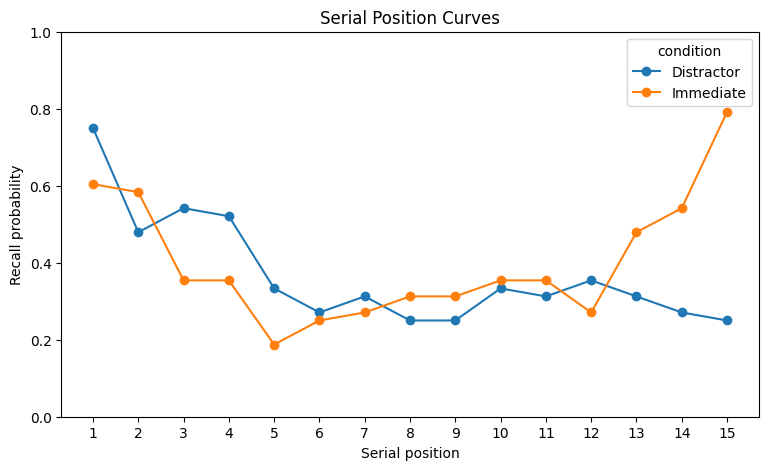

Recency difference=0.224, t=4.425, p=0.000057


mean    std
condition  region               
Distractor Middle   0.295  0.162
           Primacy  0.573  0.258
           Recency  0.297  0.223
Immediate  Middle   0.292  0.208
           Primacy  0.474  0.269
           Recency  0.521  0.267

In [3]:
curve = memory_df.groupby(["condition", "position"])["recalled"].mean().unstack(0)
ax = curve.plot(marker="o", figsize=(9, 5))
ax.set_xlabel("Serial position"); ax.set_ylabel("Recall probability")
ax.set_title("Serial Position Curves")
ax.set_ylim(0, 1); ax.set_xticks(range(1, n_positions + 1))
plt.show()

region_score = memory_df.groupby(["participant", "condition", "region"])["recalled"].mean().reset_index()
recency = region_score[region_score.region == "Recency"].pivot(index="participant", columns="condition", values="recalled")
t, p = ttest_rel(recency["Immediate"], recency["Distractor"])
diff = recency["Immediate"] - recency["Distractor"]
print(f"Recency difference={diff.mean():.3f}, t={t:.3f}, p={p:.6f}")
display(region_score.groupby(["condition", "region"])["recalled"].agg(["mean", "std"]).round(3))


## Required Extension

สร้างข้อมูลใหม่ที่มี 20 ตำแหน่งโดยปรับนิยาม Primacy เป็นตำแหน่ง 1–5 และ Recency เป็น 16–20 จากนั้นเปรียบเทียบรูปร่างของ Curve กับผลเดิม


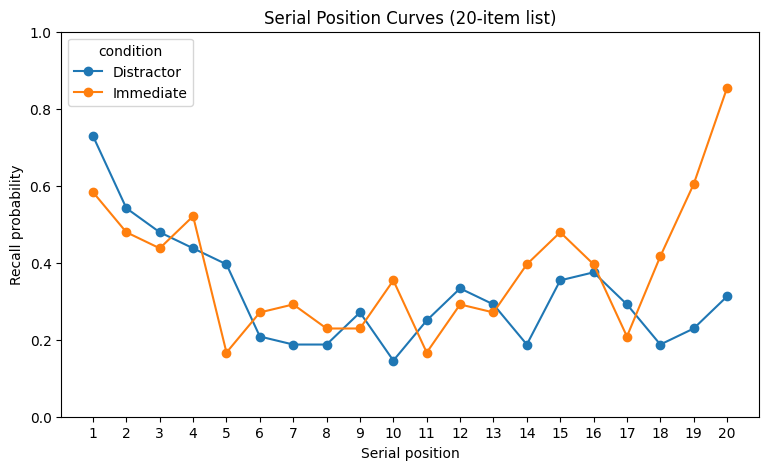

[20-item] Recency difference=0.217, t=5.317, p=0.000003


mean    std
condition  region               
Distractor Middle   0.242  0.147
           Primacy  0.517  0.193
           Recency  0.279  0.192
Immediate  Middle   0.298  0.163
           Primacy  0.438  0.228
           Recency  0.496  0.206

In [4]:
# ===== Required Extension: รายการคำ 20 ตำแหน่ง =====
# Primacy = ตำแหน่ง 1–5, Recency = 16–20, ที่เหลือเป็น Middle
rng20 = np.random.default_rng(seed + 40)
n_pos20 = 20
rows20 = []
for participant in range(1, 49):
    ability = rng20.normal(0, 0.05)
    for condition in ["Immediate", "Distractor"]:
        for position in range(1, n_pos20 + 1):
            primacy = 0.45 * np.exp(-(position - 1) / 2.2)
            recency_strength = 0.60 if condition == "Immediate" else 0.05
            recency = recency_strength * np.exp(-(n_pos20 - position) / 1.8)
            probability = np.clip(0.25 + primacy + recency + ability, 0.05, 0.95)
            recalled = rng20.binomial(1, probability)
            region = "Primacy" if position <= 5 else ("Recency" if position >= 16 else "Middle")
            rows20.append([participant, condition, position, region, recalled])
memory20_df = pd.DataFrame(rows20, columns=["participant", "condition", "position", "region", "recalled"])

# Serial position curve ของรายการ 20 คำ
curve20 = memory20_df.groupby(["condition", "position"])["recalled"].mean().unstack(0)
ax = curve20.plot(marker="o", figsize=(9, 5))
ax.set_xlabel("Serial position")
ax.set_ylabel("Recall probability")
ax.set_title("Serial Position Curves (20-item list)")
ax.set_ylim(0, 1); ax.set_xticks(range(1, n_pos20 + 1))
plt.show()

# ทดสอบผล Distractor ต่อ Recency เหมือนเดิม
region20 = memory20_df.groupby(["participant", "condition", "region"])["recalled"].mean().reset_index()
recency20 = region20[region20.region == "Recency"].pivot(index="participant", columns="condition", values="recalled")
t20, p20 = ttest_rel(recency20["Immediate"], recency20["Distractor"])
diff20 = recency20["Immediate"] - recency20["Distractor"]
print(f"[20-item] Recency difference={diff20.mean():.3f}, t={t20:.3f}, p={p20:.6f}")
display(region20.groupby(["condition", "region"])["recalled"].agg(["mean", "std"]).round(3))


## คำถามวิเคราะห์ Lab 03

**1. Primacy และ Recency ปรากฏในข้อมูลอย่างไร**

เห็นเป็นเส้นโค้งรูปตัว U ครับ ตำแหน่งต้นๆ (Primacy) จำได้ดี ~0.47–0.57 ตรงกลางตกลงมาต่ำสุด ~0.29 แล้วปลายรายการ (Recency) เด้งขึ้นมาอีกในเงื่อนไข Immediate ~0.52 คือจำของต้นกับท้ายได้ดีกว่าตรงกลาง ตรงตามทฤษฎี Serial Position

**2. Distractor Task ส่งผลต่อ Recency ตามสมมติฐานหรือไม่**

ใช่ตามสมมติฐานครับ พอมี distractor ก่อน recall ฝั่ง Recency ตกจาก ~0.52 เหลือ ~0.30 (ต่างกัน ~0.22, t ≈ 4.4, p < .001) แต่ฝั่ง Primacy แทบไม่ขยับ แปลว่า distractor ไปลบของที่ยังค้างอยู่ใน working memory ทำให้ปลายรายการหายไป แต่ไม่กระทบของต้นรายการที่เข้า long-term ไปแล้ว

**3. ผลเกี่ยวข้องกับ Working Memory และ Long-term Memory อย่างไร**

Recency มาจาก working memory คือของท้ายๆ ยังค้างอยู่ในหัวเลยตอบได้ทันที แต่พอโดน distractor มากวนก็หลุดหมด ส่วน Primacy มาจาก long-term memory เพราะของต้นรายการได้ทวนซ้ำหลายรอบเลยเข้าความจำระยะยาวไปแล้ว distractor เลยลบไม่ได้ ผลนี้เลยหนุนโมเดลความจำแบบหลายระบบ (แยก WM กับ LTM)

**4. การเพิ่มรายการเป็น 20 คำเปลี่ยน Curve อย่างไร**

รูปทรงยังเป็นตัว U เหมือนเดิม Primacy กับ Recency ยังอยู่ และ distractor ก็ยังกด recency ลง (diff ~0.22, t ≈ 5.3, p < .001) ที่ต่างคือช่วง Middle ยาวขึ้นและยังจมต่ำอยู่ (~0.24–0.30) เพราะของตรงกลางเยอะขึ้นแต่ก็ไม่ได้จำดีขึ้น สรุปคือความยาวรายการไม่ได้เปลี่ยนกลไก แค่ทำให้โซนกลางที่จำแย่กว้างขึ้น

**5. ข้อจำกัดของการใช้ข้อมูลจำลองแทน Free Recall จริงคืออะไร**

ข้อมูลนี้เราตั้งสูตร primacy/recency ไว้เองแน่ๆ effect เลยสวยเกินจริง ของจริงมีเรื่อง chunking, ความคุ้นของคำ, กลยุทธ์การจำแต่ละคน และ order ที่คนเลือกตอบ ซึ่งจำลองไม่ครบ อีกอย่างของจริงคนจำเป็นชุด/เชื่อมโยงกัน ไม่ได้จำแต่ละคำเป็นอิสระแบบ binomial แบบนี้ เลยเอาไปสรุปเป็นคนจริงตรงๆ ไม่ได้


## Reflection และ Checklist ก่อนส่ง

เขียน Reflection 150–250 คำ โดยอธิบายส่วนที่ยากที่สุด สิ่งที่ค้นพบเกี่ยวกับกระบวนการรู้คิด และสิ่งที่จะปรับปรุงหากทำการทดลองซ้ำ

**Reflection:**

ส่วนที่ยากสุดสำหรับผมคือ Required Extension ตอนต้องปรับนิยาม Primacy/Recency ให้เข้ากับรายการ 20 คำ ต้องระวังตรงเงื่อนไข region ว่าตำแหน่ง 1–5 กับ 16–20 และไม่ให้ลืมเปลี่ยน n_positions ในสูตร recency ด้วย ตอนแรกลืมแก้เลยได้กราฟเพี้ยน กว่าจะจับได้ก็งงอยู่พักนึง

สิ่งที่เข้าใจมากขึ้นคือ recency กับ primacy มันมาจากคนละระบบความจำจริงๆ เห็นชัดตอน distractor มากดเฉพาะ recency ให้หายไปแต่ primacy ยังอยู่ มันเลยทำให้เข้าใจว่าทำไมนักจิตวิทยาถึงแยก working memory กับ long-term memory ออกจากกัน และพอเพิ่มเป็น 20 คำแล้วรูปทรงยังเหมือนเดิมก็ยิ่งมั่นใจว่าเป็นผลเชิงกลไก ไม่ใช่บังเอิญจากความยาวรายการ

ถ้าทำซ้ำ ผมอยากใส่ตัวแปรพวกความคุ้นเคยของคำหรือ chunking เข้าไปในโมเดลด้วย เพราะของจริงคนไม่ได้จำทีละคำแบบอิสระ และอยากลองเก็บข้อมูลจากเพื่อนจริงมาวาด serial position curve เทียบกับข้อมูลจำลอง น่าจะเห็นว่าเส้นจริงมี noise มากกว่านี้เยอะ

### เกณฑ์ประเมิน

| ด้าน | คะแนน |
|---|---:|
| ความถูกต้องของโปรแกรมและผลลัพธ์ | 35 |
| กระบวนการวิเคราะห์และความสมเหตุสมผล | 20 |
| กราฟ ตาราง และการสื่อสารผล | 15 |
| การตีความตามหลัก Cognitive Science | 20 |
| คุณภาพโค้ดและ Reflection | 10 |
| **รวม** | **100** |

- [x] เปลี่ยน `STUDENT_ID` แล้ว
- [x] รันทุกเซลล์โดยไม่มี Error
- [x] ทำ Required Extension สำเร็จ
- [x] ตอบคำถามทุกข้อด้วยถ้อยคำของตนเอง
- [x] ตรวจไฟล์ `.ipynb` และ `.pdf` ก่อนส่ง
